<a href="https://colab.research.google.com/github/Shashi-kumar-g/machine-learning-26/blob/main/Day10_shashi069.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 10: Scaling up & Optimising on Diamonds

**Goal:** clean + encode the diamonds data, time three models (Linear, KNN, Tree), tune efficiently, analyse residuals, then score the test set exactly once.

**Golden rules observed**
- Split first, then explore/impute/scale/encode — everything inside a `Pipeline`.
- `random_state=42` everywhere, `KFold(n_splits=5, shuffle=True, random_state=42)`.
- Test file opened **only** in the final cell.
- Report RMSE, MAE, R² together.
- Every fit / predict timed with `time.perf_counter()`.

In [ ]:
import time, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, KFold, RandomizedSearchCV, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 50)
sns.set_style("whitegrid")
%matplotlib inline

def report(model, X, y, name="model"):
    """Fit-free report: model must already be fitted."""
    p = model.predict(X)
    return {"model": name,
            "RMSE": float(np.sqrt(mean_squared_error(y, p))),
            "MAE":  float(mean_absolute_error(y, p)),
            "R2":   float(r2_score(y, p))}

CUT_ORDER     = ["Fair","Good","Very Good","Premium","Ideal"]
COLOR_ORDER   = ["J","I","H","G","F","E","D"]
CLARITY_ORDER = ["I1","SI2","SI1","VS2","VS1","VVS2","VVS1","IF"]
ORDINAL = ["cut","color","clarity"]

## Load training file only (test is opened at the very end)

In [ ]:
# Load the Diamonds training dataset.
# Keep diamonds_train.csv beside this notebook, or update the candidate paths below.
import os

def locate_dataset(candidates, label):
    for path in candidates:
        if os.path.isfile(path):
            return path
    checked = "\n".join(f"  - {path}" for path in candidates)
    raise FileNotFoundError(
        f"Could not find {label}. Checked these locations:\n{checked}\n"
        "Place the CSV beside this notebook or edit the candidate paths."
    )

train_path = locate_dataset([
    "diamonds_train.csv",
    os.path.join(os.getcwd(), "diamonds_train.csv"),
    "/mnt/data/diamonds_train.csv",
], "diamonds_train.csv")

train = pd.read_csv(train_path)
print("Training CSV:", os.path.abspath(train_path))
print("Train shape:", train.shape)
train.head()


train shape: (37757, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.51,Fair,F,SI1,65.2,57.0,1193,5.03,5.09,3.30
1,0.36,Ideal,G,VVS1,60.0,56.0,892,4.66,4.69,2.81
2,1.01,Very Good,F,SI1,62.8,60.0,5010,6.32,6.38,3.99
3,0.42,Ideal,E,VS2,61.7,56.0,1024,4.82,4.80,2.97
4,0.36,Ideal,H,SI1,61.4,56.0,684,4.56,4.59,2.81


## Step 1 (0–10 min): Inspect and clean

- Drop physically impossible rows (`x==0` or `y==0` or `z==0`).
- Drop extreme outliers (`y > 20` or `z > 10`).
- Plot `price` vs `np.log(price)`.

In [ ]:
print(train.shape)
display(train.describe().T)

print("\nZero counts:")
print((train[["x","y","z"]] == 0).sum())

print("\nLargest y values:")
display(train[["y","z"]].sort_values("y").tail(5))
print("\nLargest z values:")
display(train[["y","z"]].sort_values("z").tail(5))

(37757, 10)


,count,mean,std,min,25%,50%,75%,max
carat,37757.0,0.798954,0.475055,0.2,0.40,0.70,1.04,5.01
depth,37757.0,61.749432,1.430900,43.0,61.00,61.80,62.50,79.00
table,37757.0,57.460286,2.240980,43.0,56.00,57.00,59.00,95.00
price,37757.0,3937.092592,3988.658245,326.0,952.00,2411.00,5330.00,18823.00
x,37757.0,5.733594,1.122127,0.0,4.72,5.70,6.54,10.74
y,37757.0,5.737160,1.154509,0.0,4.72,5.71,6.54,58.90
z,37757.0,3.539694,0.695240,0.0,2.91,3.53,4.04,8.06



Zero counts:
x     4
y     4
z    12
dtype: int64

Largest y values:


,y,z
33374,10.10,6.17
16115,10.16,6.72
20725,10.54,6.98
23225,31.80,5.12
10273,58.90,8.06



Largest z values:


,y,z
13689,9.48,6.38
36046,9.85,6.43
16115,10.16,6.72
20725,10.54,6.98
10273,58.90,8.06


In [ ]:
before = len(train)
mask_bad = (train["x"] == 0) | (train["y"] == 0) | (train["z"] == 0)
mask_ext = (train["y"] > 20) | (train["z"] > 10) | (train["x"] > 20)
train = train[~(mask_bad | mask_ext)].copy()
print(f"Removed {before - len(train)} rows. New shape: {train.shape}")

Removed 14 rows. New shape: (37743, 10)


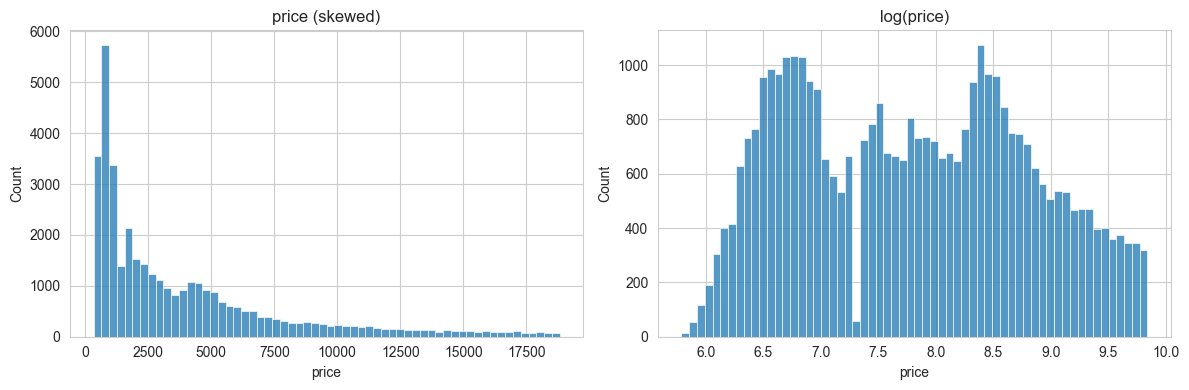

skew(price)     = 1.615528694112705
skew(log price) = 0.11304388601226029


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
sns.histplot(train["price"], bins=60, ax=ax[0]).set_title("price (skewed)")
sns.histplot(np.log(train["price"]), bins=60, ax=ax[1]).set_title("log(price)")
plt.tight_layout(); plt.show()

print("skew(price)     =", train["price"].skew())
print("skew(log price) =", np.log(train["price"]).skew())

**Why log?** The raw target is strongly right-skewed and grows non-linearly with `carat`. Log-transform makes the error approximately homoscedastic and turns multiplicative errors into additive ones, so RMSE/MAE on the log target corresponds to *percentage* errors on the dollar scale.

## Step 2 (10–20 min): Encoding and feature engineering

- Ordinal-encode `cut / color / clarity` with the known orders.
- Add `volume = x*y*z`, `carat_sq = carat**2`, `table_depth = table/depth`.
- Scale numeric features (needed for KNN and polynomial LR).

In [ ]:
def add_features(d):
    d = d.copy()
    d["volume"]      = d["x"] * d["y"] * d["z"]
    d["carat_sq"]    = d["carat"] ** 2
    d["table_depth"] = d["table"] / d["depth"]
    return d

train_fe = add_features(train)

FEATURES = ["carat","cut","color","clarity","depth","table",
            "x","y","z","volume","carat_sq","table_depth"]
NUMERIC  = ["carat","depth","table","x","y","z","volume","carat_sq","table_depth"]

X = train_fe[FEATURES]
y_log = np.log(train_fe["price"])

# split FIRST (golden rule #1)
X_tr, X_va, y_tr, y_va = train_test_split(
    X, y_log, test_size=0.20, random_state=RANDOM_STATE)
print("train:", X_tr.shape, "valid:", X_va.shape)

train: (30194, 12) valid: (7549, 12)


In [ ]:
ordinal_pipe = Pipeline([
    ("ord", OrdinalEncoder(categories=[CUT_ORDER, COLOR_ORDER, CLARITY_ORDER]))
])

def make_pre(scale=True, ordinal=False, degree=None):
    cat_tf = ordinal_pipe if ordinal else OneHotEncoder(handle_unknown="ignore")

    num_steps = [("imp", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("sc", StandardScaler()))
    if degree is not None:
        num_steps.append(("poly", PolynomialFeatures(degree=degree, include_bias=False)))

    return ColumnTransformer([
        ("num", Pipeline(num_steps), NUMERIC),
        ("cat", cat_tf, ORDINAL),
    ])

## Step 3 (20–35 min): Three models with timing

In [ ]:
def timed(model, Xa, ya, Xb):
    t0 = time.perf_counter(); model.fit(Xa, ya); fit_s = time.perf_counter() - t0
    t0 = time.perf_counter(); p = model.predict(Xb); pred_s = time.perf_counter() - t0
    return fit_s, pred_s, p

In [ ]:
results = []

# Linear regression (one-hot + scaling)
lin = Pipeline([("pre", make_pre(scale=True, ordinal=False)),
                ("m",   LinearRegression())])
f, p, pred = timed(lin, X_tr, y_tr, X_va)
results.append({"model":"Linear (one-hot)",
                "fit_s":f, "pred_s":p,
                "RMSE":float(np.sqrt(mean_squared_error(y_va, pred))),
                "MAE": float(mean_absolute_error(y_va, pred)),
                "R2":  float(r2_score(y_va, pred))})

# KNN kd_tree
knn = Pipeline([("pre", make_pre(scale=True, ordinal=False)),
                ("m",   KNeighborsRegressor(n_neighbors=5, algorithm="kd_tree", n_jobs=-1))])
f, p, pred = timed(knn, X_tr, y_tr, X_va)
results.append({"model":"KNN kd_tree (k=5)",
                "fit_s":f, "pred_s":p,
                "RMSE":float(np.sqrt(mean_squared_error(y_va, pred))),
                "MAE": float(mean_absolute_error(y_va, pred)),
                "R2":  float(r2_score(y_va, pred))})

# Decision tree
tree = Pipeline([("pre", make_pre(scale=False, ordinal=True)),
                 ("m",   DecisionTreeRegressor(random_state=RANDOM_STATE))])
f, p, pred = timed(tree, X_tr, y_tr, X_va)
results.append({"model":"DecisionTree (ordinal)",
                "fit_s":f, "pred_s":p,
                "RMSE":float(np.sqrt(mean_squared_error(y_va, pred))),
                "MAE": float(mean_absolute_error(y_va, pred)),
                "R2":  float(r2_score(y_va, pred))})

res_df = pd.DataFrame(results).set_index("model")
display(res_df.round(4))

,fit_s,pred_s,RMSE,MAE,R2
model,,,,,
Linear (one-hot),0.3835,0.0229,0.1286,0.1005,0.9841
KNN kd_tree (k=5),0.5385,0.9814,0.1575,0.1160,0.9761
DecisionTree (ordinal),0.9718,0.0268,0.1287,0.0883,0.9840


,n_train,predict_s
0,5000,0.389346
1,10000,0.429730
2,20000,0.710868


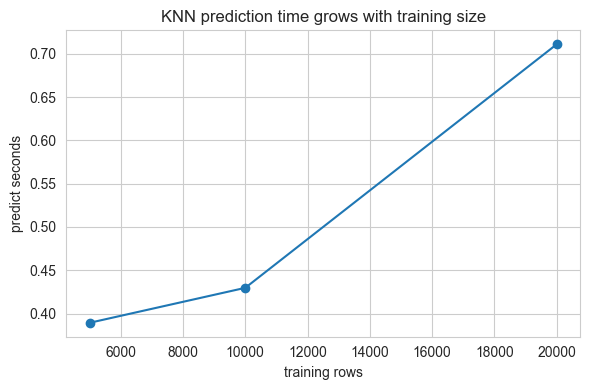

In [ ]:
sizes = [5_000, 10_000, 20_000, 40_000]
times = []
Xs_pool = X_tr.reset_index(drop=True); ys_pool = y_tr.reset_index(drop=True)

for n in sizes:
    if n > len(Xs_pool):
        continue
    Xn, yn = Xs_pool.iloc[:n], ys_pool.iloc[:n]
    model = Pipeline([("pre", make_pre(scale=True, ordinal=False)),
                      ("m", KNeighborsRegressor(n_neighbors=5, algorithm="kd_tree", n_jobs=-1))])
    model.fit(Xn, yn)
    t0 = time.perf_counter()
    _ = model.predict(X_va)
    times.append((n, time.perf_counter() - t0))

tt = pd.DataFrame(times, columns=["n_train","predict_s"])
display(tt)

plt.figure(figsize=(6,4))
plt.plot(tt["n_train"], tt["predict_s"], marker="o")
plt.xlabel("training rows"); plt.ylabel("predict seconds")
plt.title("KNN prediction time grows with training size")
plt.tight_layout(); plt.show()

**Why does KNN get slower?** KNN is a lazy learner — at predict time it must compare each query to every stored training point (kd-tree is only a constant-factor win). A decision tree does a fixed depth-bounded traversal regardless of n.

## Step 4 (35–50 min): Optimise

In [ ]:
sub = train_fe.sample(frac=0.10, random_state=RANDOM_STATE)
Xs = add_features(sub)[FEATURES]
ys = np.log(sub["price"])
print("subsample:", Xs.shape)

subsample: (3774, 12)


In [ ]:
tree_pipe = Pipeline([("pre", make_pre(scale=False, ordinal=True)),
                      ("m", DecisionTreeRegressor(random_state=RANDOM_STATE))])

tree_dist = {
    "m__max_depth":        [None, 8, 12, 16, 20, 24, 32],
    "m__min_samples_leaf": [1, 2, 5, 10, 20, 50],
    "m__min_samples_split":[2, 5, 10, 20],
}

cv5 = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
tree_search = RandomizedSearchCV(tree_pipe, tree_dist, n_iter=30, cv=cv5,
                                 scoring="neg_root_mean_squared_error",
                                 random_state=RANDOM_STATE, n_jobs=-1, verbose=0)
t0 = time.perf_counter(); tree_search.fit(Xs, ys)
print(f"tree search: {time.perf_counter()-t0:.1f}s  best={tree_search.best_params_}")
print(f"best CV RMSE (log): {-tree_search.best_score_:.4f}")

tree search: 9.9s  best={'m__min_samples_split': 5, 'm__min_samples_leaf': 5, 'm__max_depth': 20}
best CV RMSE (log): 0.1463


In [ ]:
knn_pipe = Pipeline([("pre", make_pre(scale=True, ordinal=False)),
                     ("m", KNeighborsRegressor(n_jobs=-1))])

knn_dist = {
    "m__n_neighbors": list(range(3, 31, 2)),
    "m__weights":     ["uniform","distance"],
    "m__algorithm":   ["brute","kd_tree"],
    "m__p":           [1, 2],
}

knn_search = RandomizedSearchCV(knn_pipe, knn_dist, n_iter=25, cv=cv5,
                                scoring="neg_root_mean_squared_error",
                                random_state=RANDOM_STATE, n_jobs=-1)
t0 = time.perf_counter(); knn_search.fit(Xs, ys)
print(f"KNN search: {time.perf_counter()-t0:.1f}s  best={knn_search.best_params_}")
print(f"best CV RMSE (log): {-knn_search.best_score_:.4f}")

KNN search: 4.9s  best={'m__weights': 'distance', 'm__p': 1, 'm__n_neighbors': 7, 'm__algorithm': 'kd_tree'}
best CV RMSE (log): 0.1865


In [ ]:
best_tree = Pipeline([("pre", make_pre(scale=False, ordinal=True)),
                      ("m", DecisionTreeRegressor(random_state=RANDOM_STATE,
                                                  **{k.split("__")[1]: v
                                                     for k, v in tree_search.best_params_.items()}))])

best_knn = Pipeline([("pre", make_pre(scale=True, ordinal=False)),
                     ("m", KNeighborsRegressor(n_jobs=-1,
                                               **{k.split("__")[1]: v
                                                  for k, v in knn_search.best_params_.items()}))])

rows = []
for name, mdl in [("Tree (tuned)", best_tree), ("KNN (tuned)", best_knn)]:
    f, p, pred = timed(mdl, X_tr, y_tr, X_va)
    rows.append({"model": name, "fit_s": f, "pred_s": p,
                 "RMSE_log": float(np.sqrt(mean_squared_error(y_va, pred))),
                 "MAE_log":  float(mean_absolute_error(y_va, pred)),
                 "R2_log":   float(r2_score(y_va, pred))})
display(pd.DataFrame(rows).round(4))

,model,fit_s,pred_s,RMSE_log,MAE_log,R2_log
0,Tree (tuned),0.6942,0.0272,0.1124,0.0815,0.9878
1,KNN (tuned),0.5254,1.1978,0.1383,0.1004,0.9815


In [ ]:
poly_lin = Pipeline([("pre", make_pre(scale=True, ordinal=True, degree=2)),
                     ("m", LinearRegression())])

f, p, pred = timed(poly_lin, X_tr, y_tr, X_va)
n_feat = poly_lin.named_steps["pre"].fit_transform(X_tr, y_tr).shape[1]
print(f"Polynomial(deg=2) on 9 numerics + 3 ordinals -> {n_feat} features")

print({"model":"Linear + Poly(2)","fit_s":f,"pred_s":p,
       "RMSE_log":float(np.sqrt(mean_squared_error(y_va, pred))),
       "MAE_log": float(mean_absolute_error(y_va, pred)),
       "R2_log":  float(r2_score(y_va, pred)),
       "n_features": int(n_feat)})

Polynomial(deg=2) on 9 numerics + 3 ordinals -> 57 features
{'model': 'Linear + Poly(2)', 'fit_s': 0.3842918999998801, 'pred_s': 0.04068069999993895, 'RMSE_log': 0.12637013603322617, 'MAE_log': 0.09648911816040062, 'R2_log': 0.9845886093979943, 'n_features': 57}


**Cost of `PolynomialFeatures(degree=2)` on 9 numeric features:**  
With squares + interactions (bias excluded): `9 + 9*8/2 = 45` polynomial columns. Combined with the categorical encodings the design matrix becomes much wider, and LinearRegression's `fit` is O(n_features² · n_samples).

## Step 5 (50–60 min): Residual analysis & final test score

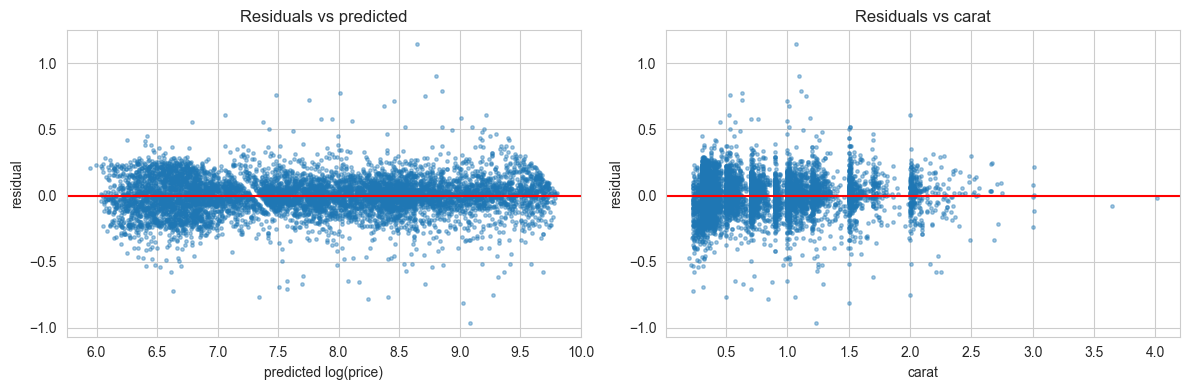

In [ ]:
best_model = best_knn   # or best_tree / poly_lin
pred_log = best_model.predict(X_va)
resid = y_va - pred_log

fig, ax = plt.subplots(1, 2, figsize=(12,4))
ax[0].scatter(pred_log, resid, s=6, alpha=.4); ax[0].axhline(0, color="r")
ax[0].set_xlabel("predicted log(price)"); ax[0].set_ylabel("residual"); ax[0].set_title("Residuals vs predicted")

ax[1].scatter(X_va["carat"], resid, s=6, alpha=.4); ax[1].axhline(0, color="r")
ax[1].set_xlabel("carat"); ax[1].set_ylabel("residual"); ax[1].set_title("Residuals vs carat")
plt.tight_layout(); plt.show()

In [ ]:
err = pd.DataFrame({
    "y_true_log": y_va.values, "y_pred_log": pred_log,
    "abs_err": np.abs(y_va.values - pred_log)
}, index=X_va.index).sort_values("abs_err", ascending=False)

err["y_true_$"] = np.exp(err["y_true_log"])
err["y_pred_$"] = np.exp(err["y_pred_log"])
display(err.head(20).round(2))

,y_true_log,y_pred_log,abs_err,y_true_$,y_pred_$
24451,9.79,8.65,1.14,17909.0,5706.46
13823,8.12,9.09,0.96,3375.0,8829.77
19811,9.71,8.80,0.90,16406.0,6647.26
19707,8.22,9.03,0.81,3696.0,8313.70
28109,9.65,8.85,0.79,15464.0,6990.83
6351,7.47,8.25,0.78,1749.0,3810.52
26663,8.79,8.01,0.78,6549.0,3007.40
308,7.64,8.41,0.77,2080.0,4492.41
37272,8.25,7.49,0.76,3827.0,1782.38
13516,6.58,7.34,0.76,720.0,1545.82


### Diagnosis of where the model fails

1. **Funnel / heteroscedasticity** — the residual cloud widens with predicted price. Logging the target tames this.
2. **Large residuals at high carat** — fewer samples in that region and price grows super-linearly with carat.
3. **Positive residual clusters at low carat but high clarity/colour** — the model under-values small perfect stones.

**Two ideas to fix it**
- Add `carat × clarity` (or `carat × color`) interaction, or fit separate models for small vs large carat.
- Winsorise / clip extreme residuals, or use a gradient-boosted tree that handles interactions natively.

In [ ]:
# ---- The test file is opened exactly one time ----
test_path = locate_dataset([
    "diamonds_test.csv",
    os.path.join(os.getcwd(), "diamonds_test.csv"),
    "/mnt/data/diamonds_test.csv",
], "diamonds_test.csv")

print("Test CSV:", os.path.abspath(test_path))
test = pd.read_csv(test_path)

test_fe = add_features(test)
X_te = test_fe[FEATURES]
y_te = test_fe["price"]
y_te_log = np.log(y_te)

final_model = Pipeline([("pre", make_pre(scale=True, ordinal=False)),
                        ("m", KNeighborsRegressor(n_jobs=-1,
                              **{k.split("__")[1]: v for k, v in knn_search.best_params_.items()}))])
final_model.fit(X, y_log)

pred_te_log = final_model.predict(X_te)

rmse_log = np.sqrt(mean_squared_error(y_te_log, pred_te_log))
mae_log  = mean_absolute_error(y_te_log, pred_te_log)
r2_log   = r2_score(y_te_log, pred_te_log)

rmse_usd = np.sqrt(mean_squared_error(y_te, np.exp(pred_te_log)))
mae_usd  = mean_absolute_error(y_te, np.exp(pred_te_log))

print(f"FINAL TEST (log target)  RMSE={rmse_log:.4f}  MAE={mae_log:.4f}  R2={r2_log:.4f}")
print(f"FINAL TEST (USD)         RMSE=${rmse_usd:,.0f}  MAE=${mae_usd:,.0f}  R2={r2_log:.4f}")


FINAL TEST (log target)  RMSE=0.1354  MAE=0.0974  R2=0.9824
FINAL TEST (USD)         RMSE=$724  MAE=$356  R2=0.9824


## Self-test answers

1. **Why KNN prediction slows with training size** — it must compare each query to every stored point (kd-tree gives only a constant-factor win in high dimension). Prediction cost is O(n·d).
2. **Residual** = `y_true − y_pred`. A good residual plot shows a horizontal band centred on zero with roughly constant spread — no funnel, no curve.
3. **log(price)** compresses the right tail, makes error symmetric / homoscedastic, and turns multiplicative (percentage) error into additive.
4. **`x = 0`** values are physically impossible → data errors that must be dropped.
5. **Subsample tuning** gives ~10× speed-up with a very similar hyper-parameter ranking; only the top candidates need full-set re-evaluation. It fails when the sample is too small to represent rare regions.
6. **Poly(2) on 9 features** → `9 + 9*8/2 = 45` output columns (squares + interactions).

## Checkpoint answers

1. Tree traversal is O(depth) ≤ O(log n) and touches no other data; KNN must scan the whole stored set.
2. Funnel = heteroscedasticity. Log target re-expresses error as percentage error and flattens the funnel.
3. Loss surface in hyper-parameters is usually smooth → ranking transfers. Fails with rare regions or heavy-tailed metrics.
4. RMSE — it squares residuals, so one huge error dominates. MAE is linear and more robust.

## Deliverables checklist

| Deliverable | Location |
|---|---|
| Accuracy vs time table (3 models) | Step 3b |
| Subsample-then-confirm tuning log | Steps 4b–4d |
| Residual plots + diagnosis | Step 5a |
| Final test metrics (RMSE $ / MAE $ / R²) | Step 5c |

## Stretch ideas

- Winsorise `y` / `z` at 0.1 / 99.9 percentiles.
- Fit two KNNs: `carat < 1` and `carat >= 1`.
- Report MAPE on the dollar scale:
```python
mape = np.mean(np.abs((y_te - np.exp(pred_te_log)) / y_te)) * 100
print(f"MAPE = {mape:.2f}%")
```